[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Winfredy/SadTalker/blob/main/quick_demo.ipynb)

### SadTalker：Learning Realistic 3D Motion Coefficients for Stylized Audio-Driven Single Image Talking Face Animation

[arxiv](https://arxiv.org/abs/2211.12194) | [project](https://sadtalker.github.io) | [Github](https://github.com/Winfredy/SadTalker)

Wenxuan Zhang, Xiaodong Cun, Xuan Wang, Yong Zhang, Xi Shen, Yu Guo, Ying Shan, Fei Wang.

Xi'an Jiaotong University, Tencent AI Lab, Ant Group

CVPR 2023

TL;DR: A realistic and stylized talking head video generation method from a single image and audio


Installation (around 5 mins)

In [1]:
### make sure that CUDA is available in Edit -> Nootbook settings -> GPU
!nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv,noheader

Tesla T4, 15360 MiB, 14913 MiB


In [2]:
!update-alternatives --install /usr/local/bin/python3 python3 /usr/bin/python3.8 2
!update-alternatives --install /usr/local/bin/python3 python3 /usr/bin/python3.9 1
!sudo apt install python3.8

!sudo apt-get install python3.8-distutils

!python --version

!apt-get update

!apt install software-properties-common

!sudo dpkg --remove --force-remove-reinstreq python3-pip python3-setuptools python3-wheel

!apt-get install python3-pip

print('Git clone project and install requirements...')
!git clone https://github.com/Winfredy/SadTalker &> /dev/null
%cd SadTalker
!export PYTHONPATH=/content/SadTalker:$PYTHONPATH
!python3.8 -m pip install torch==1.12.1+cu113 torchvision==0.13.1+cu113 torchaudio==0.12.1 --extra-index-url https://download.pytorch.org/whl/cu113
!apt update
!apt install ffmpeg &> /dev/null
!python3.8 -m pip install -r requirements.txt

update-alternatives: error: alternative path /usr/bin/python3.8 doesn't exist
update-alternatives: error: alternative path /usr/bin/python3.9 doesn't exist
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libnsl2 libpython3.8-minimal libpython3.8-stdlib python3.8-minimal
Suggested packages:
  python3.8-venv binfmt-support
The following NEW packages will be installed:
  libnsl2 libpython3.8-minimal libpython3.8-stdlib python3.8 python3.8-minimal
0 upgraded, 5 newly installed, 0 to remove and 33 not upgraded.
Need to get 4,744 kB of archives.
After this operation, 18.6 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/main amd64 libnsl2 amd64 1.3.0-3build3 [41.4 kB]
Get:2 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 libpython3.8-minimal amd64 3.8.20-1+noble1 [745 kB]
Get:3 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubu

In [11]:
%cd /content/SadTalker

!python3.8 -m pip install basicsr==1.4.2

/content/SadTalker
  Using cached basicsr-1.4.2.tar.gz (172 kB)
  Preparing metadata (setup.py) ... done
  Using cached addict-2.4.0-py3-none-any.whl.metadata (1.0 kB)
  Using cached future-1.0.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached lmdb-2.1.1.tar.gz (913 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached PyYAML-6.0.3-cp38-cp38-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.1 kB)
  Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
  Using cached tb_nightly-2.14.0a20230808-py3-none-any.whl.metadata (1.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached yapf-0.43.0-py3-none-any.whl.metadata (46 kB)
  Using cached networkx-3.1-py3-none-any.whl.metadata (5.3 kB)
  Using cach

In [12]:
%cd /content/SadTalker

!python3.8 -m pip install --only-binary=:all: lmdb==1.4.1

!python3.8 -c "import torch; print('PyTorch:', torch.__version__); print('CUDA available:', torch.cuda.is_available())"

/content/SadTalker
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 298.9/298.9 kB 7.9 MB/s eta 0:00:00
Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 24, in <module>
    from . import multiarray
  File "/usr/lib/python3/dist-packages/numpy/core/multiarray.py", line 10, in <module>
    from . import overrides
  File "/usr/lib/python3/dist-packages/numpy/core/overrides.py", line 8, in <module>
    from numpy.core._multiarray_umath import (
ModuleNotFoundError: No module named 'numpy.core._multiarray_umath'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/__init__.py", line 130, in <module>
    from numpy.__config__ import show as show_config
  File "/usr/lib/python3/dist-packages/numpy/__config__.py", line 4, in <module>
    from numpy.core._multiarray_umath import (
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 5

In [15]:
%cd /content

!python3.8 -c "import numpy; print('NumPy version:', numpy.__version__); print('NumPy path:', numpy.__file__)"

!python3.8 -m pip check

/content
Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 24, in <module>
    from . import multiarray
  File "/usr/lib/python3/dist-packages/numpy/core/multiarray.py", line 10, in <module>
    from . import overrides
  File "/usr/lib/python3/dist-packages/numpy/core/overrides.py", line 8, in <module>
    from numpy.core._multiarray_umath import (
ModuleNotFoundError: No module named 'numpy.core._multiarray_umath'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/__init__.py", line 130, in <module>
    from numpy.__config__ import show as show_config
  File "/usr/lib/python3/dist-packages/numpy/__config__.py", line 4, in <module>
    from numpy.core._multiarray_umath import (
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 50, in <module>
    raise ImportError(msg)
ImportError: 

IMPORTANT: PLEASE READ THIS FOR A

In [16]:
!python3.8 -m pip install --user --force-reinstall --no-cache-dir --only-binary=:all: numpy==1.24.4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 102.9 MB/s eta 0:00:00
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [17]:
!python3.8 -c "import numpy; print('NumPy version:', numpy.__version__); print('NumPy location:', numpy.__file__)"

NumPy version: 1.24.4
NumPy location: /root/.local/lib/python3.8/site-packages/numpy/__init__.py


In [18]:
!python3.8 -c "import torch; print('PyTorch:', torch.__version__); print('CUDA available:', torch.cuda.is_available())"

PyTorch: 1.12.1+cu113
CUDA available: True


In [21]:
%cd /content/SadTalker

!python3.8 -m pip install --user -v --no-cache-dir filterpy==1.4.5 2>&1 | tee /content/filterpy_error.log

/content/SadTalker
Using pip 24.0 from /usr/lib/python3/dist-packages/pip (python 3.8)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 8.5 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info
  writing /tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/dependency_links.txt
  writing requirements to /tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/requires.txt
  writing top-level names to /tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-j10mkfp9/filterpy.egg-info/SOURCES.txt'
  reading manifest template 'MANIFEST.in'
  /usr/lib/python3/dist-packages/setuptools/dist.py:744: SetuptoolsDeprecationWarning: Invalid dash-separ

In [23]:
!python3.8 -m pip install --user --no-build-isolation --no-use-pep517 filterpy==1.4.5

  Using cached filterpy-1.4.5.zip (177 kB)
  Preparing metadata (setup.py) ... done
  Using cached matplotlib-3.7.5-cp38-cp38-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.7 kB)
  Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
  Using cached contourpy-1.1.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.57.0-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (102 kB)
  Using cached kiwisolver-1.4.7-cp38-cp38-manylinux_2_5_x86_64.manylinux1_x86_64.whl.metadata (6.3 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached importlib_resources-6.4.5-py3-none-any.whl.metadata (4.0 kB)
Using cached matplotlib-3.7.5-cp38-cp38-manylinux_2_12_x86_64.manylinux2010_x86_64.whl (9.2 MB)
Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x

In [25]:
%cd /content/SadTalker

!python3.8 -m pip install --user --upgrade "setuptools<70" wheel
!python3.8 -m pip install --user --no-build-isolation filterpy==1.4.5

/content/SadTalker
  Using cached wheel-0.45.1-py3-none-any.whl.metadata (2.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 894.6/894.6 kB 19.0 MB/s eta 0:00:00
Using cached wheel-0.45.1-py3-none-any.whl (72 kB)
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Using cached filterpy-1.4.5.zip (177 kB)
  Preparing metadata (setup.py) ... done
  Using cached scipy-1.10.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (58 kB)
  Using cached matplotlib-3.7.5-cp38-cp38-manylinux_2_12_x86_64.manylinux2010_x86_64.whl.metadata (5.7 kB)
  Using cached contourpy-1.1.1-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (5.9 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.57.0-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (102 kB)
  Using cached kiwisolver-1.4.7-cp38-cp38-manylinux_2_5_x86_64.manylinux1_x86_64.whl.metadata (6.3 k

In [27]:
%cd /content/SadTalker

!python3.8 -c "import numpy, torch, filterpy, lmdb; print('All four imports successful!'); print('NumPy:', numpy.__version__); print('PyTorch:', torch.__version__); print('CUDA available:', torch.cuda.is_available())"

/content/SadTalker
All four imports successful!
NumPy: 1.24.4
PyTorch: 1.12.1+cu113
CUDA available: True


In [28]:
%cd /content/SadTalker

!python3.8 -m pip install --user --upgrade "setuptools<70" wheel
!python3.8 -m pip install --user --no-build-isolation basicsr==1.4.2

/content/SadTalker
  Using cached basicsr-1.4.2.tar.gz (172 kB)
  Preparing metadata (setup.py) ... done
  Using cached addict-2.4.0-py3-none-any.whl.metadata (1.0 kB)
  Using cached future-1.0.0-py3-none-any.whl.metadata (4.0 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached PyYAML-6.0.3-cp38-cp38-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (2.1 kB)
  Using cached scikit_image-0.21.0-cp38-cp38-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (14 kB)
  Using cached tb_nightly-2.14.0a20230808-py3-none-any.whl.metadata (1.8 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached yapf-0.43.0-py3-none-any.whl.metadata (46 kB)
  Using cached networkx-3.1-py3-none-any.whl.metadata (5.3 kB)
  Using cached imageio-2.35.1-py3-none-any.whl.metadata (4.9 kB)
  Using cached tifffile-2023.7.10-py3-none-any.whl.metadata (31 kB)
  Using cached PyWavelets-1.4.1-cp38-cp38-manylin

In [29]:
!python3.8 -c "import basicsr; print('BasicSR is working!')"

BasicSR is working!


In [31]:
%cd /content/SadTalker

!ls
!ls checkpoints
!ls inference.py

/content/SadTalker
app_sadtalker.py  examples	LICENSE		  req.txt	      src
checkpoints	  gfpgan	predict.py	  requirements3d.txt  webui.bat
cog.yaml	  inference.py	quick_demo.ipynb  requirements.txt    webui.sh
docs		  launcher.py	README.md	  scripts
mapping_00109-model.pth.tar  SadTalker_V0.0.2_256.safetensors
mapping_00229-model.pth.tar  SadTalker_V0.0.2_512.safetensors
inference.py


In [32]:
%cd /content/SadTalker

!python3.8 -c "import numpy, torch, filterpy, lmdb, basicsr; print('All imports successful!'); print('NumPy:', numpy.__version__); print('PyTorch:', torch.__version__); print('CUDA:', torch.cuda.is_available())"

/content/SadTalker
All imports successful!
NumPy: 1.24.4
PyTorch: 1.12.1+cu113
CUDA: True


In [26]:
!python3.8 -c "import filterpy; print('FilterPy is working!')"

FilterPy is working!


In [33]:
%cd /content/SadTalker

!ls -lah examples/source_image
!ls -lah examples/driven_audio

/content/SadTalker
total 23M
drwxr-xr-x 2 root root 4.0K Oct 15 13:53 .
drwxr-xr-x 5 root root 4.0K Oct 15 13:53 ..
-rw-r--r-- 1 root root 733K Oct 15 13:53 art_0.png
-rw-r--r-- 1 root root 556K Oct 15 13:53 art_10.png
-rw-r--r-- 1 root root 478K Oct 15 13:53 art_11.png
-rw-r--r-- 1 root root 705K Oct 15 13:53 art_12.png
-rw-r--r-- 1 root root 618K Oct 15 13:53 art_13.png
-rw-r--r-- 1 root root 636K Oct 15 13:53 art_14.png
-rw-r--r-- 1 root root 658K Oct 15 13:53 art_15.png
-rw-r--r-- 1 root root 1.5M Oct 15 13:53 art_16.png
-rw-r--r-- 1 root root 2.0M Oct 15 13:53 art_17.png
-rw-r--r-- 1 root root 115K Oct 15 13:53 art_18.png
-rw-r--r-- 1 root root 462K Oct 15 13:53 art_19.png
-rw-r--r-- 1 root root 478K Oct 15 13:53 art_1.png
-rw-r--r-- 1 root root 694K Oct 15 13:53 art_20.png
-rw-r--r-- 1 root root 813K Oct 15 13:53 art_2.png
-rw-r--r-- 1 root root 1.3M Oct 15 13:53 art_3.png
-rw-r--r-- 1 root root 3.5M Oct 15 13:53 art_4.png
-rw-r--r-- 1 root root 1.2M Oct 15 13:53 art_5.png
-rw-r-

In [34]:
%cd /content/SadTalker

!ls -lah examples/source_image
!ls -lah examples/driven_audio

/content/SadTalker
total 23M
drwxr-xr-x 2 root root 4.0K Oct 15 13:53 .
drwxr-xr-x 5 root root 4.0K Oct 15 13:53 ..
-rw-r--r-- 1 root root 733K Oct 15 13:53 art_0.png
-rw-r--r-- 1 root root 556K Oct 15 13:53 art_10.png
-rw-r--r-- 1 root root 478K Oct 15 13:53 art_11.png
-rw-r--r-- 1 root root 705K Oct 15 13:53 art_12.png
-rw-r--r-- 1 root root 618K Oct 15 13:53 art_13.png
-rw-r--r-- 1 root root 636K Oct 15 13:53 art_14.png
-rw-r--r-- 1 root root 658K Oct 15 13:53 art_15.png
-rw-r--r-- 1 root root 1.5M Oct 15 13:53 art_16.png
-rw-r--r-- 1 root root 2.0M Oct 15 13:53 art_17.png
-rw-r--r-- 1 root root 115K Oct 15 13:53 art_18.png
-rw-r--r-- 1 root root 462K Oct 15 13:53 art_19.png
-rw-r--r-- 1 root root 478K Oct 15 13:53 art_1.png
-rw-r--r-- 1 root root 694K Oct 15 13:53 art_20.png
-rw-r--r-- 1 root root 813K Oct 15 13:53 art_2.png
-rw-r--r-- 1 root root 1.3M Oct 15 13:53 art_3.png
-rw-r--r-- 1 root root 3.5M Oct 15 13:53 art_4.png
-rw-r--r-- 1 root root 1.2M Oct 15 13:53 art_5.png
-rw-r-

In [35]:
from google.colab import files
uploaded = files.upload()

Saving aura.png to aura.png


In [36]:
from PIL import Image
import os

os.makedirs("examples/source_image", exist_ok=True)

filename = next(iter(uploaded))
Image.open(filename).convert("RGB").save(
    "examples/source_image/aura.png"
)

print("Aura image ready!")

Aura image ready!


In [10]:
!python3.8 --version
!python3.8 -m pip --version
!nvidia-smi

Python 3.8.20
pip 24.0 from /usr/lib/python3/dist-packages/pip (python 3.8)
Thu Oct 15 14:04:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                     

Download models (1 mins)

In [3]:
print('Download pre-trained models...')
!rm -rf checkpoints
!bash scripts/download_models.sh

Download pre-trained models...
--2026-10-15 13:56:38--  https://github.com/OpenTalker/SadTalker/releases/download/v0.0.2-rc/mapping_00109-model.pth.tar
Resolving github.com (github.com)... 20.29.134.23
Connecting to github.com (github.com)|20.29.134.23|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/569518584/ccc415aa-c6f4-47ee-8250-b10bf440ba62?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-15T14%3A40%3A17Z&rscd=attachment%3B+filename%3Dmapping_00109-model.pth.tar&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-15T13%3A39%3A55Z&ske=2026-10-15T14%3A40%3A17Z&sks=b&skv=2018-11-09&sig=o2l5Pk3zKzRQ5B4BYN9xJKctPBPm9wwBBQhP1lnY%2BXQ%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MjA3NjE5OCwibmJmI

Choose the image name to animate: (saved in folder 'examples/')


/tmp/ipykernel_440/2553204973.py:6: DeprecationWarning: glob.glob1 is deprecated and will be removed in Python 3.15. Use glob.glob and pass a directory to its root_dir argument instead.
  img_list = glob.glob1('examples/source_image', '*.png')


Dropdown(index=21, options=('art_0', 'art_1', 'art_10', 'art_11', 'art_12', 'art_13', 'art_14', 'art_15', 'art…

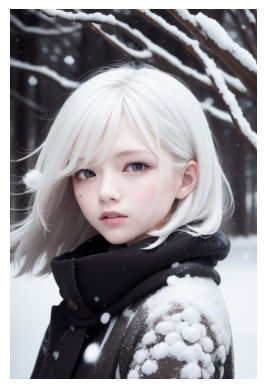

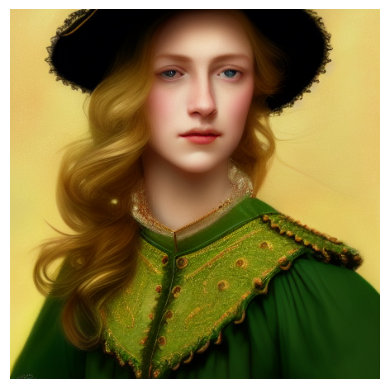

In [5]:
# borrow from makeittalk
import ipywidgets as widgets
import glob
import matplotlib.pyplot as plt
print("Choose the image name to animate: (saved in folder 'examples/')")
img_list = glob.glob1('examples/source_image', '*.png')
img_list.sort()
img_list = [item.split('.')[0] for item in img_list]
default_head_name = widgets.Dropdown(options=img_list, value='full3')
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        plt.imshow(plt.imread('examples/source_image/{}.png'.format(default_head_name.value)))
        plt.axis('off')
        plt.show()
default_head_name.observe(on_change)
display(default_head_name)
plt.imshow(plt.imread('examples/source_image/{}.png'.format(default_head_name.value)))
plt.axis('off')
plt.show()

Animation

In [6]:
# selected audio from exmaple/driven_audio
img = 'examples/source_image/{}.png'.format(default_head_name.value)
print(img)
!python3.8 inference.py --driven_audio ./examples/driven_audio/RD_Radio31_000.wav \
           --source_image {img} \
           --result_dir ./results --still --preprocess full --enhancer gfpgan

examples/source_image/art_19.png
Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 24, in <module>
    from . import multiarray
  File "/usr/lib/python3/dist-packages/numpy/core/multiarray.py", line 10, in <module>
    from . import overrides
  File "/usr/lib/python3/dist-packages/numpy/core/overrides.py", line 8, in <module>
    from numpy.core._multiarray_umath import (
ModuleNotFoundError: No module named 'numpy.core._multiarray_umath'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/lib/python3/dist-packages/numpy/__init__.py", line 130, in <module>
    from numpy.__config__ import show as show_config
  File "/usr/lib/python3/dist-packages/numpy/__config__.py", line 4, in <module>
    from numpy.core._multiarray_umath import (
  File "/usr/lib/python3/dist-packages/numpy/core/__init__.py", line 50, in <module>
    raise ImportError(msg)
ImportError: 

IMPORTANT

In [9]:
from IPython.display import HTML, display
from base64 import b64encode
import os
import glob
import sys

results_folder = "./results"

if not os.path.exists(results_folder):
    print("The results folder does not exist yet.")
    print("Run the SadTalker generation cell first.")
else:
    mp4_files = sorted(glob.glob("./results/*.mp4"))

    if not mp4_files:
        print("No MP4 video found in the results folder.")
        print("Aura's video may not have been generated successfully.")
        print("Check the previous SadTalker generation cell.")
        print("Files in results:", os.listdir(results_folder))
    else:
        mp4_name = mp4_files[-1]

        with open(mp4_name, "rb") as video_file:
            mp4 = video_file.read()

        data_url = (
            "data:video/mp4;base64,"
            + b64encode(mp4).decode("utf-8")
        )

        print("Displaying animation:", mp4_name)

        display(HTML(f"""
            <video width="400" controls>
                <source src="{data_url}" type="video/mp4">
                Your browser does not support video playback.
            </video>
        """))

The results folder does not exist yet.
Run the SadTalker generation cell first.
